Fase 1: Preprocesamiento y Limpieza de Datos.

In [1]:
import pandas as pd
import json

# 1. Cargar el archivo original
df = pd.read_csv("Conversaciones_chatbot_Salud_mental.csv")
row = df.iloc[0]

intents_limpios = []

# Iterar sobre las 80 intenciones identificadas
for i in range(80):
    tag_col = f"intents[{i}].tag"
    if tag_col in row and pd.notna(row[tag_col]):
        tag = str(row[tag_col])

        # Extraer patrones (mensajes de usuario)
        patterns = [
            str(row[c]) for c in df.columns
            if f"intents[{i}].patterns" in c and pd.notna(row[c])
        ]

        # Extraer respuestas del bot
        responses = [
            str(row[c]) for c in df.columns
            if f"intents[{i}].responses" in c and pd.notna(row[c])
        ]

        intents_limpios.append({
            "intent_id": i + 1,
            "categoria": tag,
            "num_patrones": len(patterns),
            "num_respuestas": len(responses),
            "patrones": patterns,
            "respuestas": responses
        })

# 2. Guardar el archivo JSON formateado
with open("salud_mental_limpio.json", "w", encoding="utf-8") as f:
    json.dump(intents_limpios, f, indent=2, ensure_ascii=False)

print(f"Procesadas {len(intents_limpios)} categorias con exito.")

Procesadas 80 categorias con exito.


Fase 3: Análisis Predictivo con Regresión Lineal.

Ecuacion: Y = 0.430X + 0.707
Coeficiente R2: 0.593


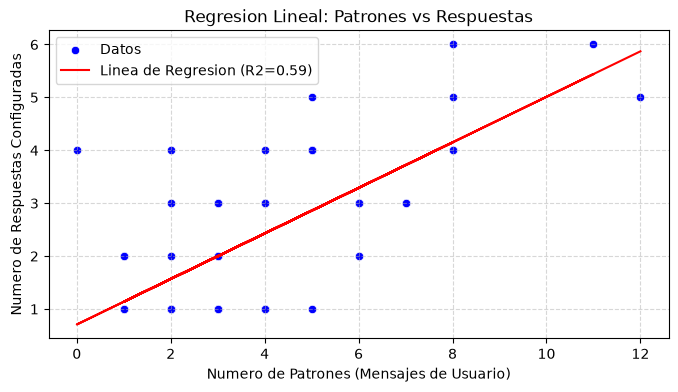

In [3]:
import pymongo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Conexion a MongoDB
client = pymongo.MongoClient("mongodb://localhost:27017/")

db = client["salud_mental_db"]
collection = db["intenciones"]

# 2. Cargar datos en Pandas
documentos = list(collection.find({}, {"_id": 0, "categoria": 1, "num_patrones": 1, "num_respuestas": 1}))
df = pd.DataFrame(documentos)

# 3. Regresion Lineal Simple
X = df[["num_patrones"]]
y = df["num_respuestas"]

modelo = LinearRegression()
modelo.fit(X, y)
y_pred = modelo.predict(X)

# 4. Metricas
m = modelo.coef_[0]
b = modelo.intercept_
r2 = r2_score(y, y_pred)

print(f"Ecuacion: Y = {m:.3f}X + {b:.3f}")
print(f"Coeficiente R2: {r2:.3f}")

# 5. Visualizacion
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="num_patrones", y="num_respuestas", color="blue", label="Datos")
plt.plot(X, y_pred, color="red", label=f"Linea de Regresion (R2={r2:.2f})")
plt.title("Regresion Lineal: Patrones vs Respuestas")
plt.xlabel("Numero de Patrones (Mensajes de Usuario)")
plt.ylabel("Numero de Respuestas Configuradas")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Reto: PLN y Regresión Lineal

Filas en la tabla: 79
Ecuacion de la Recta: Y = -115.327X + 286.141
Coeficiente de Determinacion (R2): 0.0074


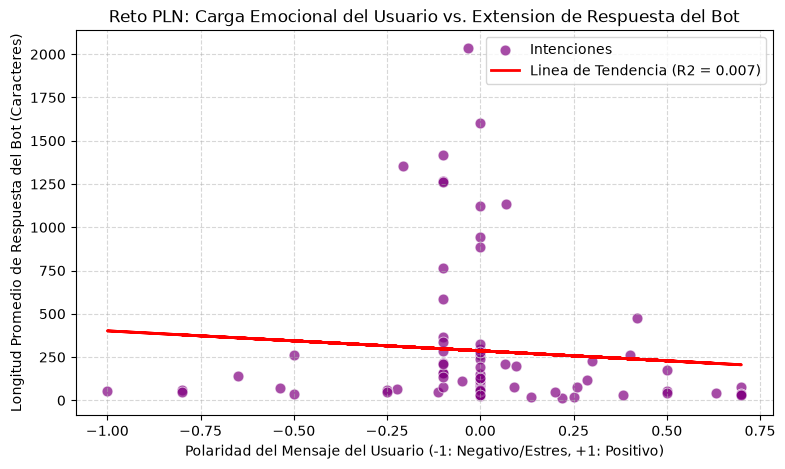

In [1]:
import pymongo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Conexion a la base de datos NoSQL
client = pymongo.MongoClient("mongodb://localhost:27017/")
db = client["salud_mental_db"]
collection = db["intenciones"]

# 2. Extraccion y Transformacion: Cualitativo - Cuantitativo (PLN)
data = []
for doc in collection.find():
    patrones = doc.get("patrones", [])
    respuestas = doc.get("respuestas", [])

    if patrones and respuestas:
        # Unir los mensajes del usuario para analizar el sentimiento global
        texto_usuario = " ".join(patrones)
        # Extraccion de caracteristicas (Feature Extraction con TextBlob)
        # polaridad: -1.0 (muy negativo) a +1.0 (muy positivo)
        sentimiento = TextBlob(texto_usuario).sentiment.polarity
        
        # Longitud media de respuesta del bot
        avg_len_respuesta = sum(len(r) for r in respuestas) / len(respuestas)
        
        data.append({
            "categoria": doc.get("categoria", "N/A"),
            "polaridad_usuario_x": sentimiento,
            "longitud_respuesta_bot_y": avg_len_respuesta
        })

df = pd.DataFrame(data)

# OPCIONAL: Comprobar cuantas filas tiene la tabla
print(f"Filas en la tabla: {len(df)}")

# 3. Entrenamiento del Modelo de Regresion Lineal
X = df[["polaridad_usuario_x"]]
y = df["longitud_respuesta_bot_y"]

modelo = LinearRegression()
modelo.fit(X, y)
y_pred = modelo.predict(X)

# 4. Calculo de Metricas Evaluativas
m = modelo.coef_[0]
b = modelo.intercept_
r2 = r2_score(y, y_pred)

print(f"Ecuacion de la Recta: Y = {m:.3f}X + {b:.3f}")
print(f"Coeficiente de Determinacion (R2): {r2:.4f}")

# 5. Visualizacion de Resultados
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="polaridad_usuario_x",
    y="longitud_respuesta_bot_y",
    color="purple",
    alpha=0.7,
    s=60,
    label="Intenciones"
)
plt.plot(X, y_pred, color="red", linewidth=2, label=f"Linea de Tendencia (R2 = {r2:.3f})")
plt.title("Reto PLN: Carga Emocional del Usuario vs. Extension de Respuesta del Bot")
plt.xlabel("Polaridad del Mensaje del Usuario (-1: Negativo/Estres, +1: Positivo)")
plt.ylabel("Longitud Promedio de Respuesta del Bot (Caracteres)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()